# Section 1 — SNA Analysis
### Blocks A, C, D  (Block B = Louvain, done in Gephi · Block E waits for Section 2)

Run top to bottom. Figures save to `figures/` at 300 dpi, ready for the report.

**Expected cross-checks** — if these don't match, stop and re-export from Gephi:
- nodes 6,434 · edges 259,122
- avg in-degree **40.274** (matches Gephi's "Average Degree")
- avg total degree **80.55**  ← Gephi reports 40.274 because for a *directed* graph it
  shows in-degree only. Both are correct; state which convention you use in the report.

In [23]:
import pandas as pd, numpy as np, networkx as nx
import matplotlib.pyplot as plt
from collections import Counter
from pathlib import Path

Path("figures").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi":120, "savefig.dpi":300, "font.size":11})

edges = pd.read_csv("data/gephi_edges.csv")
nodes = pd.read_csv("data/gephi_nodes.csv")

G = nx.DiGraph()
for r in edges.itertuples(index=False):
    G.add_edge(r.Source, r.Target, weight=int(r.Weight))
label = dict(zip(nodes.Id, nodes.Label))

n, m = G.number_of_nodes(), G.number_of_edges()
print(f"nodes {n:,} | edges {m:,}")
assert n == 6434 and m == 259122, "MISMATCH - re-export from Gephi"
print("verified against the validated dataset")

nodes 6,434 | edges 259,122
verified against the validated dataset


---
## Block A — Degree centrality

Degree is the simplest centrality: how many people you interact with. We separate
**in-degree** (people who replied to you = your reach) from **out-degree** (people you
replied to = your activity), because for influence the two mean very different things.

In [24]:
ind  = dict(G.in_degree());   outd = dict(G.out_degree())
tot  = {v: ind[v]+outd[v] for v in G}
wind = dict(G.in_degree(weight="weight"))
woutd= dict(G.out_degree(weight="weight"))

rows=[]
for name,d in [("in-degree",ind),("out-degree",outd),("total degree",tot),
               ("weighted in",wind),("weighted out",woutd)]:
    a=np.array(list(d.values()))
    rows.append({"measure":name,"mean":a.mean(),"median":np.median(a),
                 "std":a.std(),"min":a.min(),"max":a.max()})
stats=pd.DataFrame(rows).round(2)
display(stats)
stats.to_csv("figures/blockA_degree_stats.csv", index=False)

print(f"\navg in-degree {np.mean(list(ind.values())):.3f}  <- Gephi 'Average Degree' 40.274")
print(f"avg total degree {np.mean(list(tot.values())):.2f}  <- our 80.55")

,measure,mean,median,std,min,max
0,in-degree,40.27,16.0,55.05,0,1364
1,out-degree,40.27,15.0,53.87,0,964
2,total degree,80.55,30.0,106.20,4,2328
3,weighted in,48.63,18.0,73.94,0,2472
4,weighted out,48.63,17.0,70.20,0,1638



avg in-degree 40.274  <- Gephi 'Average Degree' 40.274
avg total degree 80.55  <- our 80.55


### Degree distribution and concentration

A social network is rarely uniform. We check how unequally attention is distributed, and
whether the tail follows a power law (the signature of a scale-free network).

In [25]:
t = np.array(list(tot.values()))
print("PERCENTILES (total degree)")
for p in [50,75,90,95,99,99.9]:
    print(f"  p{p:<5} = {np.percentile(t,p):8.1f}")

s=np.sort(t)[::-1]
print("\nCONCENTRATION")
conc={}
for f in [0.01,0.05,0.10,0.20]:
    k=int(n*f); share=100*s[:k].sum()/s.sum(); conc[f]=share
    print(f"  top {int(f*100):>2}% of users hold {share:5.1f}% of all degree")

cnt=Counter(t)
ks=np.array(sorted(k for k in cnt if k>0)); fs=np.array([cnt[k] for k in ks])
mask=ks>=10
slope,_=np.polyfit(np.log10(ks[mask]), np.log10(fs[mask]), 1)
alpha=-slope
print(f"\nTAIL SHAPE (k>=10): log-log slope alpha ~ {alpha:.2f}")
print("  2-3 = classic scale-free; <2 = heavier tail, hubs even more dominant")

PERCENTILES (total degree)
  p50    =     30.0
  p75    =    119.0
  p90    =    229.0
  p95    =    293.0
  p99    =    438.0
  p99.9  =    793.5

CONCENTRATION
  top  1% of users hold   7.2% of all degree
  top  5% of users hold  24.4% of all degree
  top 10% of users hold  40.4% of all degree
  top 20% of users hold  64.0% of all degree

TAIL SHAPE (k>=10): log-log slope alpha ~ 1.18
  2-3 = classic scale-free; <2 = heavier tail, hubs even more dominant


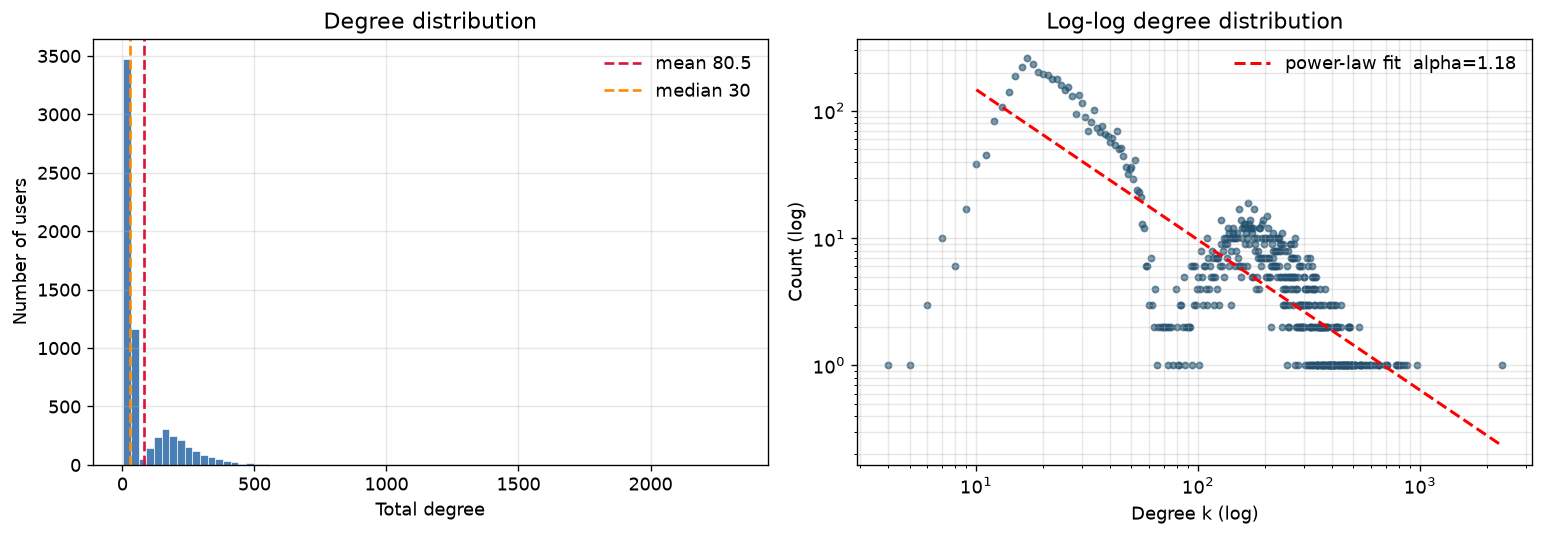

saved figures/fig_A_degree_distribution.png


In [26]:
fig,ax=plt.subplots(1,2,figsize=(13,4.6))

ax[0].hist(t,bins=80,color="#4a7fb5",edgecolor="white",linewidth=.4)
ax[0].axvline(t.mean(),color="crimson",ls="--",lw=1.6,label=f"mean {t.mean():.1f}")
ax[0].axvline(np.median(t),color="darkorange",ls="--",lw=1.6,label=f"median {np.median(t):.0f}")
ax[0].set_xlabel("Total degree"); ax[0].set_ylabel("Number of users")
ax[0].set_title("Degree distribution"); ax[0].legend(frameon=False); ax[0].grid(alpha=.3)

ax[1].scatter(ks,fs,s=14,alpha=.6,color="#22506e")
xf=np.logspace(np.log10(10),np.log10(ks.max()),50)
ax[1].plot(xf,10**(np.polyval([slope,np.polyfit(np.log10(ks[mask]),np.log10(fs[mask]),1)[1]],np.log10(xf))),
           "r--",lw=1.8,label=f"power-law fit  alpha={alpha:.2f}")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("Degree k (log)"); ax[1].set_ylabel("Count (log)")
ax[1].set_title("Log-log degree distribution"); ax[1].legend(frameon=False); ax[1].grid(alpha=.3,which="both")

plt.tight_layout(); plt.savefig("figures/fig_A_degree_distribution.png",bbox_inches="tight"); plt.show()
print("saved figures/fig_A_degree_distribution.png")

In [27]:
top=sorted(tot.items(), key=lambda x:-x[1])[:20]
hubs=pd.DataFrame([{"rank":i,"label":label.get(v,"?"),"total_degree":d,
                    "in_degree":ind[v],"out_degree":outd[v],
                    "weighted_in":wind[v],"node_id":v}
                   for i,(v,d) in enumerate(top,1)])
display(hubs)
hubs.to_csv("figures/blockA_top20_hubs.csv", index=False)
print("saved figures/blockA_top20_hubs.csv")

,rank,label,total_degree,in_degree,out_degree,weighted_in,node_id
0,1,user_00001,2328,1364,964,2472,u_7645c5aa9d5f
1,2,user_00002,964,344,620,442,u_9c2bfcf65852
2,3,user_00003,871,603,268,793,u_1b6dd7b36f8f
3,4,user_00004,846,423,423,615,u_0cb2e49a48bf
4,5,user_00005,823,390,433,550,u_da4611ffd982
5,6,user_00006,804,367,437,438,u_8f9687ab44a4
6,7,user_00007,797,449,348,550,u_9bb6bb140ded
7,8,user_00008,789,452,337,549,u_25dbb71a14bb
8,9,user_00009,781,301,480,431,u_e983e1de91c6
9,10,user_00010,711,308,403,375,u_26277852db5b


saved figures/blockA_top20_hubs.csv


---
## Block C — Density and cohesion

How tightly knit is the network, and does it hold together? Path length and diameter are
expensive on 6,434 nodes, so we **sample** source nodes and say so in the methodology
rather than letting an exact computation run for hours.

In [28]:
U = G.to_undirected()
res = {}
res["density (directed)"]      = nx.density(G)
res["reciprocity"]             = nx.reciprocity(G)
res["avg clustering (undir.)"] = nx.average_clustering(U)
res["degree assortativity"]    = nx.degree_assortativity_coefficient(G)
res["weakly conn components"]  = nx.number_weakly_connected_components(G)
res["strongly conn components"]= nx.number_strongly_connected_components(G)

core = nx.core_number(U)
res["max k-core"] = max(core.values())
for k in [10,20,50]:
    res[f"nodes in {k}-core"] = sum(1 for v in core.values() if v>=k)

for k,v in res.items():
    print(f"  {k:<26}: {v:,.5f}" if isinstance(v,float) else f"  {k:<26}: {v:,}")

  density (directed)        : 0.00626
  reciprocity               : 0.41879
  avg clustering (undir.)   : 0.07204
  degree assortativity      : -0.00920
  weakly conn components    : 1
  strongly conn components  : 25
  max k-core                : 84
  nodes in 10-core          : 6,241
  nodes in 20-core          : 3,441
  nodes in 50-core          : 1,762


In [29]:
# sampled shortest paths (exact would be O(n*m) ~ 1.7 billion ops)
import random
random.seed(42)
SAMPLE = 300
srcs = random.sample(list(U.nodes()), SAMPLE)
lengths=[]
for s0 in srcs:
    d = nx.single_source_shortest_path_length(U, s0)
    lengths.extend(d.values())
lengths=[x for x in lengths if x>0]
print(f"sampled {SAMPLE} sources -> {len(lengths):,} paths")
print(f"  average shortest path length : {np.mean(lengths):.3f}")
print(f"  median                       : {np.median(lengths):.1f}")
print(f"  approx. eccentricity (max)   : {max(lengths)}  <- lower bound on diameter")
print("\nREPORT THIS AS SAMPLED, not exact.")

sampled 300 sources -> 1,929,900 paths
  average shortest path length : 2.542
  median                       : 3.0
  approx. eccentricity (max)   : 4  <- lower bound on diameter

REPORT THIS AS SAMPLED, not exact.


### Intra- vs inter-community density

Needs `data/gephi_node_metrics.csv` exported from Gephi **after** running Modularity.
If edges concentrate *within* communities, the network has genuine group structure —
which matters later, because sensors/seeds should be spread across groups, not clustered.

In [30]:
try:
    gm = pd.read_csv("data/gephi_node_metrics.csv")
    idc = "Id" if "Id" in gm.columns else gm.columns[0]
    modc = [c for c in gm.columns if "odularity" in c][0]
    comm = dict(zip(gm[idc], gm[modc]))

    intra = sum(1 for u,v in G.edges() if comm.get(u)==comm.get(v))
    inter = m - intra
    print(f"communities            : {len(set(comm.values()))}")
    print(f"intra-community edges  : {intra:,} ({100*intra/m:.1f}%)")
    print(f"inter-community edges  : {inter:,} ({100*inter/m:.1f}%)")

    sizes = Counter(comm.values())
    big = sizes.most_common(10)
    print("\nlargest communities:", [f"{c}:{s}" for c,s in big])

    rows=[]
    for cid,size in sizes.items():
        if size<20: continue
        sub=G.subgraph([v for v in G if comm.get(v)==cid])
        rows.append({"community":cid,"nodes":size,"edges":sub.number_of_edges(),
                     "density":nx.density(sub)})
    cdf=pd.DataFrame(rows).sort_values("nodes",ascending=False).round(5)
    display(cdf.head(10))
    cdf.to_csv("figures/blockC_community_density.csv",index=False)
except FileNotFoundError:
    print("data/gephi_node_metrics.csv not found.")
    print("Run Modularity in Gephi, then Data Laboratory > Export table. Re-run this cell.")

communities            : 8
intra-community edges  : 82,234 (31.7%)
inter-community edges  : 176,888 (68.3%)

largest communities: ['2:1614', '0:1427', '3:1069', '5:737', '4:504', '1:434', '7:424', '6:225']


,community,nodes,edges,density
2,2,1614,20241,0.00777
1,0,1427,38338,0.01884
4,3,1069,12445,0.01090
6,5,737,4527,0.00835
7,4,504,1813,0.00715
5,1,434,2167,0.01153
3,7,424,2175,0.01213
0,6,225,528,0.01048


---
## Block D — Centrality comparison

Five centralities, then a **Spearman rank correlation** between them. Where two measures
disagree, they are capturing different structural roles — a *hub* (many connections) is not
the same as a *bridge* (connects otherwise separate groups). This sets up the later finding
that centrality and influence are not the same thing.

In [31]:
cent = pd.DataFrame({"node":list(G.nodes())})
cent["label"]      = cent.node.map(label)
cent["degree"]     = cent.node.map(tot)
cent["in_degree"]  = cent.node.map(ind)
cent["out_degree"] = cent.node.map(outd)
cent["pagerank"]   = cent.node.map(nx.pagerank(G, weight="weight"))
cent["core_number"]= cent.node.map(core)

try:
    gm = pd.read_csv("data/gephi_node_metrics.csv")
    idc = "Id" if "Id" in gm.columns else gm.columns[0]
    for col,new in [("Betweenness Centrality","betweenness"),
                    ("Closeness Centrality","closeness"),
                    ("Eigenvector Centrality","eigenvector")]:
        if col in gm.columns:
            cent[new]=cent.node.map(dict(zip(gm[idc],gm[col])))
            print(f"loaded {new} from Gephi")
except FileNotFoundError:
    print("no Gephi metrics yet - computing a local fallback instead")

# eigenvector fallback: the DIRECTED graph has 25 strongly-connected components, which
# makes eigenvector_centrality_numpy ambiguous. The UNDIRECTED graph is fully connected,
# so we compute it there and label it accordingly.
if "eigenvector" not in cent.columns:
    try:
        ev = nx.eigenvector_centrality_numpy(U, weight="weight")
        cent["eigenvector_undirected"] = cent.node.map(ev)
        print("computed eigenvector on the UNDIRECTED graph (directed version is ambiguous")
        print("  because the graph has 25 strongly-connected components) - note this in the report")
    except Exception as e:
        print("eigenvector unavailable:", e)

cent.to_csv("figures/blockD_centralities.csv", index=False)
display(cent.head())

computed eigenvector on the UNDIRECTED graph (directed version is ambiguous
  because the graph has 25 strongly-connected components) - note this in the report


,node,label,degree,in_degree,out_degree,pagerank,core_number,eigenvector_undirected
0,u_44176596eca7,user_01999,50,26,24,0.000089,31,0.004163
1,u_d57f77166952,user_00282,308,141,167,0.000547,84,0.033481
2,u_f6454d51902e,user_01647,113,54,59,0.000206,66,0.009535
3,u_e1686e72fc65,user_00750,216,137,79,0.000406,84,0.019583
4,u_95cb88ab48b4,user_02547,39,21,18,0.000085,24,0.002449


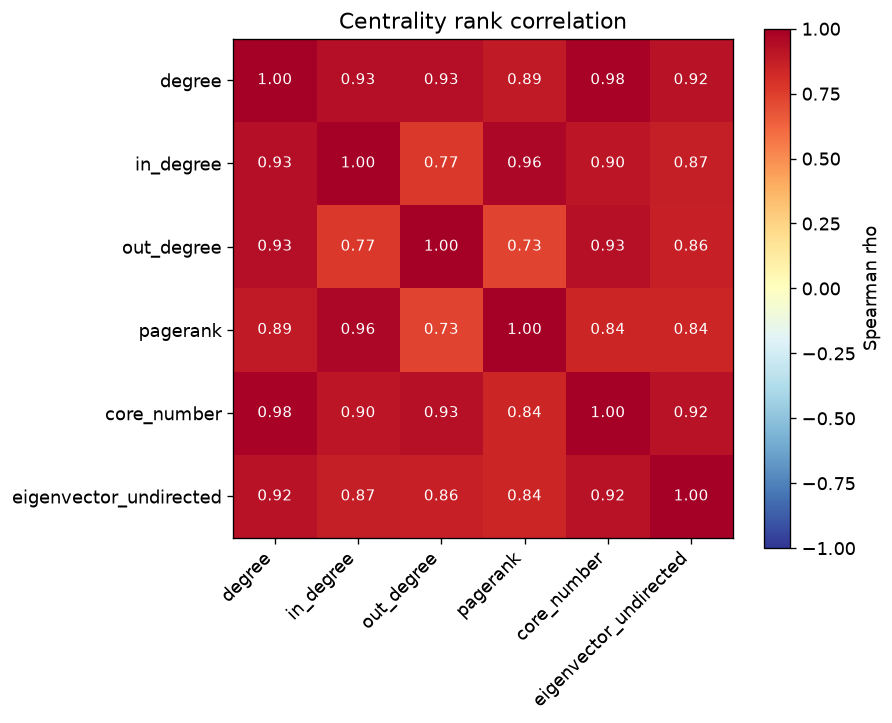

,degree,in_degree,out_degree,pagerank,core_number,eigenvector_undirected
degree,1.000,0.931,0.932,0.887,0.979,0.918
in_degree,0.931,1.000,0.766,0.963,0.902,0.870
out_degree,0.932,0.766,1.000,0.727,0.925,0.861
pagerank,0.887,0.963,0.727,1.000,0.839,0.838
core_number,0.979,0.902,0.925,0.839,1.000,0.916
eigenvector_undirected,0.918,0.870,0.861,0.838,0.916,1.000


In [32]:
num=[c for c in ["degree","in_degree","out_degree","pagerank","core_number",
                 "betweenness","closeness","eigenvector","eigenvector_undirected"]
     if c in cent.columns]
corr=cent[num].corr(method="spearman")

fig,ax=plt.subplots(figsize=(7.5,6.2))
im=ax.imshow(corr,cmap="RdYlBu_r",vmin=-1,vmax=1)
ax.set_xticks(range(len(num))); ax.set_xticklabels(num,rotation=45,ha="right")
ax.set_yticks(range(len(num))); ax.set_yticklabels(num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j,i,f"{corr.iloc[i,j]:.2f}",ha="center",va="center",
                color="white" if abs(corr.iloc[i,j])>.6 else "black",fontsize=9)
plt.colorbar(im,label="Spearman rho")
ax.set_title("Centrality rank correlation")
plt.tight_layout(); plt.savefig("figures/fig_D_centrality_correlation.png",bbox_inches="tight"); plt.show()
display(corr.round(3))
corr.to_csv("figures/blockD_correlation_matrix.csv")

In [33]:
# hubs vs bridges: high betweenness but comparatively low degree
if "betweenness" in cent.columns:
    cent["deg_rank"]=cent.degree.rank(ascending=False)
    cent["btw_rank"]=cent.betweenness.rank(ascending=False)
    cent["gap"]=cent.deg_rank-cent.btw_rank
    print("BRIDGES - rank far higher on betweenness than on degree:")
    display(cent.nlargest(10,"gap")[["label","degree","betweenness","deg_rank","btw_rank"]])
    print("HUBS - high degree but comparatively low betweenness:")
    display(cent.nsmallest(10,"gap")[["label","degree","betweenness","deg_rank","btw_rank"]])
else:
    print("Export Gephi metrics (with Network Diameter run) to enable this.")

Export Gephi metrics (with Network Diameter run) to enable this.


---
## Section 1 outputs

| File | Use |
|---|---|
| `figures/fig_A_degree_distribution.png` | Report figure |
| `figures/fig_D_centrality_correlation.png` | Report figure |
| `figures/blockA_degree_stats.csv` | Stats table |
| `figures/blockA_top20_hubs.csv` | Hub table |
| `figures/blockC_community_density.csv` | Community table |
| `figures/blockD_centralities.csv` | Feeds Section 2 baselines |

**Block E** (communities vs influence) comes after Section 2, since it needs CELF's seeds.